<a href="https://colab.research.google.com/github/thammarat-ai/geo-notes/blob/main/day01_points_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 1 · Points — 83 จุดดูดาวทั่วไทย
### #30DayMapChallenge 2026 · ทำแผนที่ธีมท้องฟ้ายามค่ำคืนด้วย matplotlib

โน้ตบุ๊กนี้ทำแผนที่จุด (Points) จากข้อมูล **83 เขตอนุรักษ์ท้องฟ้ามืด (Dark Sky Thailand)**
ของสถาบันวิจัยดาราศาสตร์แห่งชาติ (NARIT) — รันทุกเซลล์ตามลำดับ (**Runtime → Run all**)
แล้วจะได้ภาพแผนที่พร้อมดาวน์โหลดท้ายโน้ตบุ๊กครับ


In [1]:
# ติดตั้งฟอนต์ภาษาไทย Noto Sans Thai (รันเซลล์นี้ก่อนเซลล์อื่นเสมอ)
import urllib.request
from fontTools.ttLib import TTFont
from fontTools.varLib.instancer import instantiateVariableFont
from matplotlib import font_manager

# โหลด variable font แล้วสร้างไฟล์ static (Regular + Bold)
# หมายเหตุ: ใช้ Noto Sans Thai เพราะวาดสระบน/วรรณยุกต์ซ้อนกัน (เช่น ทั่ว) ได้ถูกต้อง
urllib.request.urlretrieve(
    "https://github.com/google/fonts/raw/main/ofl/notosansthai/"
    "NotoSansThai%5Bwdth%2Cwght%5D.ttf",
    "NotoSansThai-VF.ttf",
)
for _name, _wght in [("NotoSansThai-Regular", 400), ("NotoSansThai-Bold", 700)]:
    _f = TTFont("NotoSansThai-VF.ttf")
    instantiateVariableFont(_f, {"wght": _wght, "wdth": 100}, inplace=True)
    _f.save(f"{_name}.ttf")
    font_manager.fontManager.addfont(f"{_name}.ttf")

print("ติดตั้งฟอนต์ไทย Noto Sans Thai เรียบร้อย")

ติดตั้งฟอนต์ไทย Noto Sans Thai เรียบร้อย


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon, Circle
from matplotlib.font_manager import FontProperties
import urllib.request

# ใช้ฟอนต์ Noto Sans Thai (วาดสระบน/วรรณยุกต์ซ้อนกันได้ถูกต้อง)
plt.rcParams["font.family"] = "Noto Sans Thai"

FP_B = FontProperties(family="Noto Sans Thai", weight="bold")
FP_R = FontProperties(family="Noto Sans Thai")

# เช็กว่าฟอนต์ไทยพร้อมใช้
thai_ok = any(f.name == "Noto Sans Thai"
              for f in matplotlib.font_manager.fontManager.ttflist)
print("ฟอนต์ไทยพร้อม:", thai_ok)

ฟอนต์ไทยพร้อม: True


## 1. โหลดข้อมูล

- **จุดดูดาว 83 แห่ง**: ลองโหลดจาก GitHub ก่อน (ต้อง push ไฟล์ `darksky_thailand.csv`
  ไว้ที่ `geo-notes/data/` ก่อน) — ถ้าโหลดไม่ได้ จะมีปุ่มให้อัปโหลดไฟล์เอง
- **ขอบประเทศไทย**: โหลดจาก GADM v4.1 โดยตรง (ละเอียด มีรูปเกาะด้วย)


In [3]:
# --- จุดดูดาว 83 แห่ง ---
CSV_URL = "https://raw.githubusercontent.com/thammarat-ai/geo-notes/main/data/darksky_thailand.csv"
try:
    pts = pd.read_csv(CSV_URL)
    print(f"โหลดจาก GitHub สำเร็จ: {len(pts)} จุด")
except Exception as e:
    print("โหลดจาก URL ไม่ได้:", e)
    print("→ กรุณากดปุ่ม Choose Files แล้วอัปโหลดไฟล์ darksky_thailand.csv")
    from google.colab import files
    up = files.upload()
    pts = pd.read_csv(next(iter(up)))
    print(f"โหลดจากไฟล์ที่อัปโหลด: {len(pts)} จุด")

print(pts["region"].value_counts().to_string())

# --- ขอบประเทศไทย (GADM v4.1) ---
with urllib.request.urlopen(
    "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_THA_0.json",
    timeout=60,
) as r:
    gj = json.load(r)
geom = gj["features"][0]["geometry"]
polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
print(f"โหลดขอบประเทศสำเร็จ: {len(polys)} polygon")

โหลดจาก GitHub สำเร็จ: 83 จุด
region
northeast    37
north        23
south         7
eastern       6
center        6
western       4
โหลดขอบประเทศสำเร็จ: 595 polygon


## 2. วาดแผนที่

เทคนิคหลัก:
1. พื้นหลังสีน้ำเงินเข้ม + จุดดาวพื้นหลังสุ่ม → บรรยากาศท้องฟ้ายามค่ำคืน
2. ขอบประเทศสีฟ้าอ่อน
3. จุดดูดาววาด 2 ชั้นซ้อนกัน — ชั้นล่างจาง ๆ เป็น **halo** ชั้นบนเป็น **core** ขอบขาว → ดูเรืองแสง
4. แยกสีตามภาค 6 ภาค


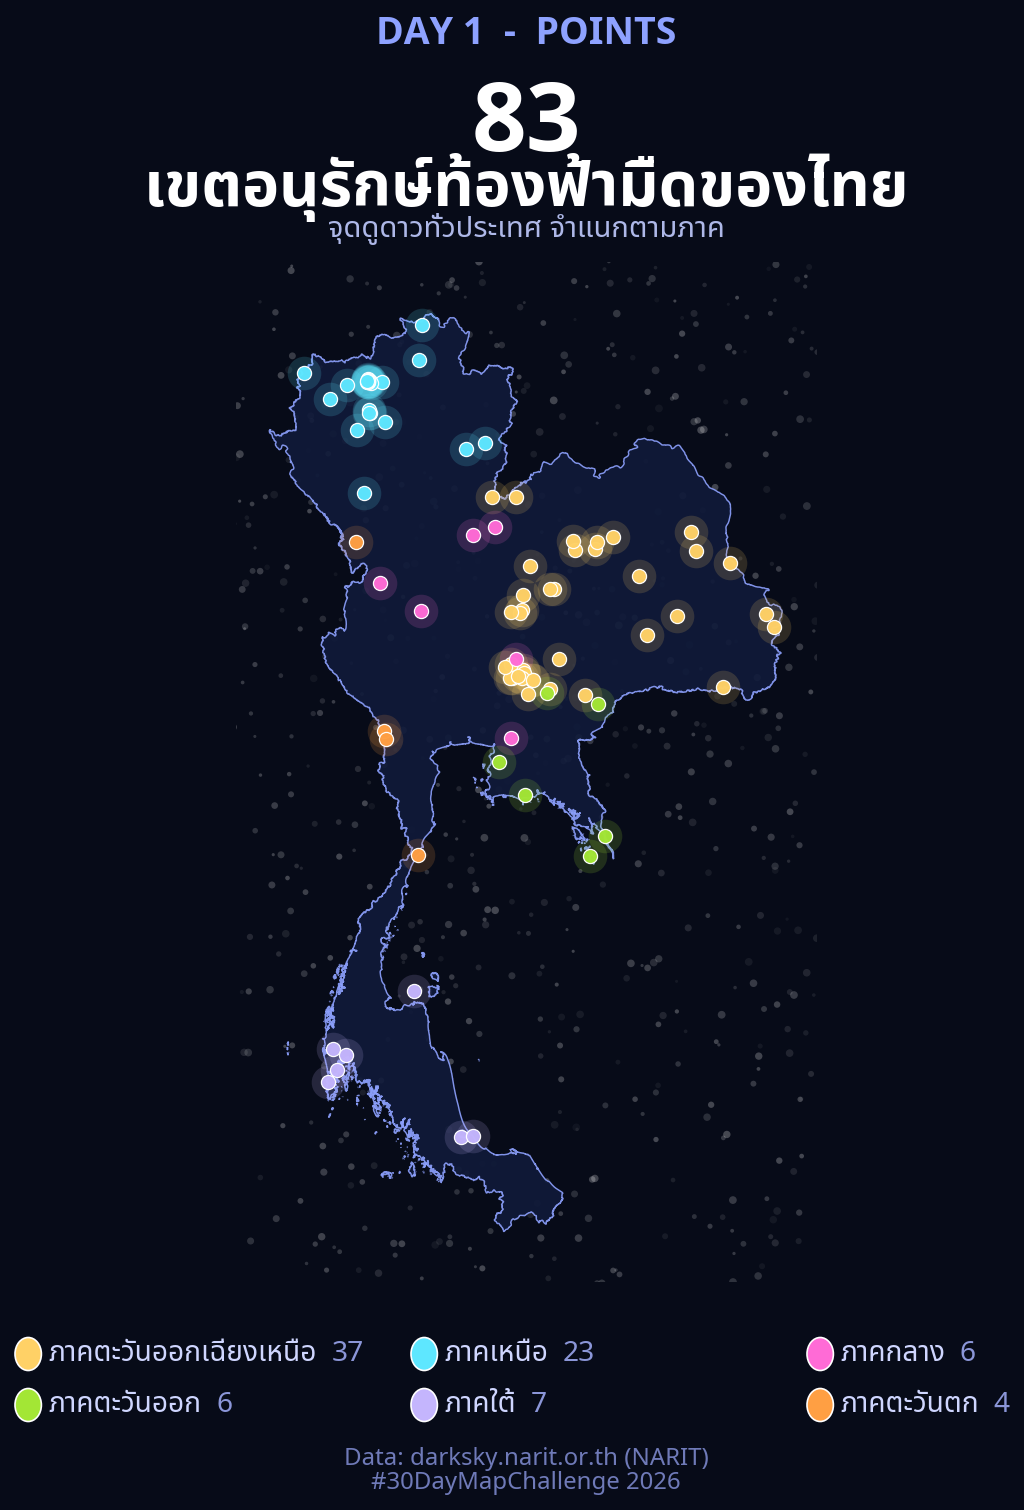

In [4]:
REGIONS = [  # (รหัสภาค, ชื่อไทย, สี)
    ("northeast", "ภาคตะวันออกเฉียงเหนือ", "#ffd166"),
    ("north",     "ภาคเหนือ",              "#5ee7ff"),
    ("center",    "ภาคกลาง",               "#ff6bd6"),
    ("eastern",   "ภาคตะวันออก",            "#a3e635"),
    ("south",     "ภาคใต้",                "#c4b5fd"),
    ("western",   "ภาคตะวันตก",             "#ff9f43"),
]

W, H = 1600, 2000
fig = plt.figure(figsize=(W / 200, H / 200), dpi=150)
fig.patch.set_facecolor("#070b18")
ax = fig.add_axes([0.04, 0.14, 0.92, 0.68])
ax.set_facecolor("#070b18")

# ดาวพื้นหลัง
rng = np.random.default_rng(30)
ax.scatter(rng.uniform(96.5, 106.5, 700), rng.uniform(4.5, 21.5, 700),
           s=rng.uniform(2, 14, 700), c="white",
           alpha=rng.uniform(0.04, 0.25, 700), linewidths=0, zorder=1)

# ขอบประเทศไทย
for poly in polys:
    ax.add_patch(MplPolygon(np.asarray(poly[0]), closed=True,
                            facecolor="#101a3a", edgecolor="#8ea2ff",
                            lw=0.7, alpha=0.9, zorder=2))

# จุดดูดาวแยกตามภาค
for key, th_label, color in REGIONS:
    g = pts[pts["region"] == key]
    x, y = g["longitude"].values, g["latitude"].values
    ax.scatter(x, y, s=260, c=color, alpha=0.16, linewidths=0, zorder=3)  # halo
    ax.scatter(x, y, s=46, c=color, edgecolors="white", linewidths=0.6,
               alpha=0.98, zorder=4)                                      # core

ax.set_xlim(96.8, 106.2)
ax.set_ylim(4.8, 21.3)
ax.set_aspect("equal")
ax.axis("off")

# หัวเรื่อง
fig.text(0.5, 0.972, "DAY 1  -  POINTS", ha="center", va="center",
         fontproperties=FP_B, fontsize=18, color="#8ea2ff")
fig.text(0.5, 0.910, "83", ha="center", va="center",
         fontproperties=FP_B, fontsize=46, color="white")
fig.text(0.5, 0.870, "เขตอนุรักษ์ท้องฟ้ามืดของไทย", ha="center", va="center",
         fontproperties=FP_B, fontsize=30, color="white")
fig.text(0.5, 0.842, "จุดดูดาวทั่วประเทศ จำแนกตามภาค",
         ha="center", va="center", fontproperties=FP_R,
         fontsize=14, color="#aeb8e8")

# legend ทำมือ 2 แถว x 3 คอลัมน์
ly, lx = [0.092, 0.058], [0.14, 0.47, 0.80]
thai_txts = []
for i, (key, th_label, color) in enumerate(REGIONS):
    n = int((pts["region"] == key).sum())
    cx, cy = lx[i % 3], ly[i // 3]
    fig.patches.extend([Circle((cx - 0.055, cy), 0.011, color=color,
                               ec="white", lw=0.8,
                               transform=fig.transFigure, figure=fig, zorder=5)])
    t = fig.text(cx - 0.038, cy, th_label, ha="left", va="center",
                 fontproperties=FP_R, fontsize=13.5, color="#cfd6ff")
    thai_txts.append((t, n))

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for t, n in thai_txts:  # วางตัวเลขต่อท้ายข้อความไทยโดยวัดความกว้างจริง
    bb = t.get_window_extent(renderer).transformed(fig.transFigure.inverted())
    fig.text(bb.x1 + 0.012, (bb.y0 + bb.y1) / 2, f"{n}",
             ha="left", va="center", fontproperties=FP_R,
             fontsize=13.5, color="#8b96d8")

fig.text(0.5, 0.022, "Data: darksky.narit.or.th (NARIT)",
         ha="center", va="center", fontproperties=FP_R,
         fontsize=11.5, color="#6f7ab8")
fig.text(0.5, 0.006, "#30DayMapChallenge 2026",
         ha="center", va="center", fontproperties=FP_R,
         fontsize=11.5, color="#6f7ab8")

plt.show()

## 3. บันทึกและดาวน์โหลดภาพ


In [5]:
fig.savefig("day01_points_darksky_thailand.png", dpi=200, facecolor="#070b18")
from google.colab import files
files.download("day01_points_darksky_thailand.png")
print("ดาวน์โหลดภาพแล้ว 🎉")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ดาวน์โหลดภาพแล้ว 🎉
